In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)


In [5]:
data=np.loadtxt("inputDataset.txt")
x=data[:,:-1]
y=data[:,-1]

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
   x,
    y,
    test_size=0.30,
    random_state=50
)

In [37]:
lda = LinearDiscriminantAnalysis()
qda = QuadraticDiscriminantAnalysis()

lda.fit(X_train, y_train)
qda.fit(X_train, y_train)

y_pred_lda = lda.predict(X_test)
y_pred_qda = qda.predict(X_test)

In [38]:
print(classification_report(y_test, y_pred_lda))

              precision    recall  f1-score   support

         0.0       0.80      0.80      0.80        92
         1.0       0.61      0.60      0.60        47

    accuracy                           0.73       139
   macro avg       0.70      0.70      0.70       139
weighted avg       0.73      0.73      0.73       139



In [39]:
print(classification_report(y_test, y_pred_qda))

              precision    recall  f1-score   support

         0.0       0.82      0.82      0.82        92
         1.0       0.64      0.64      0.64        47

    accuracy                           0.76       139
   macro avg       0.73      0.73      0.73       139
weighted avg       0.76      0.76      0.76       139



In [40]:
cm_lda = confusion_matrix(y_test, y_pred_lda)

print(cm_lda)

[[74 18]
 [19 28]]


In [41]:
cm_qda = confusion_matrix(y_test, y_pred_qda)

print(cm_qda)

[[75 17]
 [17 30]]


In [42]:
results = pd.DataFrame({
    "Model": ["LDA", "QDA"],
    
    "Accuracy": [
        accuracy_score(y_test, y_pred_lda),
        accuracy_score(y_test, y_pred_qda)
    ],
    
    "Precision": [
        precision_score(y_test, y_pred_lda),
        precision_score(y_test, y_pred_qda)
    ],
    
    "Recall (Sensitivity)": [
        recall_score(y_test, y_pred_lda),
        recall_score(y_test, y_pred_qda)
    ]
})

print(results)

  Model  Accuracy  Precision  Recall (Sensitivity)
0   LDA  0.733813   0.608696              0.595745
1   QDA  0.755396   0.638298              0.638298


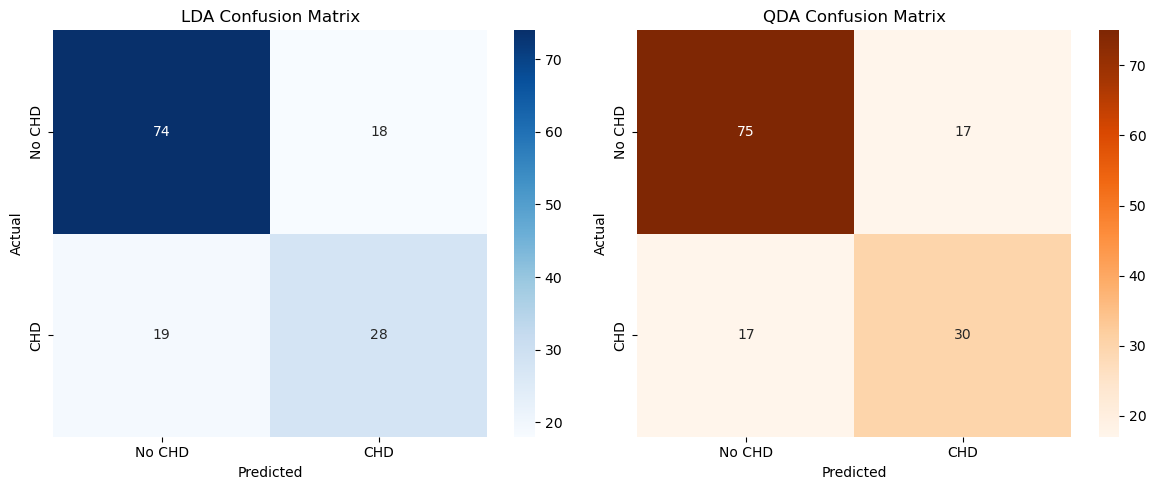

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_lda,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0],
    xticklabels=["No CHD", "CHD"],
    yticklabels=["No CHD", "CHD"]
)

axes[0].set_title("LDA Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")


sns.heatmap(
    cm_qda,
    annot=True,
    fmt="d",
    cmap="Oranges",
    ax=axes[1],
    xticklabels=["No CHD", "CHD"],
    yticklabels=["No CHD", "CHD"]
)

axes[1].set_title("QDA Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [45]:
print("LDA False Negatives:", cm_lda[1, 0])
print("QDA False Negatives:", cm_qda[1, 0])

LDA False Negatives: 19
QDA False Negatives: 17
